# 03 — Preprocessing du dataset pour le Supervised Learning

**Projet Data Mining — USTHB / M2 SII 2026-2027 — ERA5-Land mensuel, Algérie (grille réduite 2×2)**

Ce notebook part du fichier produit par le notebook 01 (`data/processed/era5_algeria_masked_2x2_v2.nc`) et s'appuie sur les résultats du notebook 02 (EDA). Il produit un dataset prêt à l'emploi pour KNN / SVM / Random Forest / Voting / AdaBoost.

**Ordre des traitements appliqué (justifié dans le rapport PDF) :**

| # | Étape | Pourquoi à cette place |
|---|---|---|
| 1 | Chargement + conversion d'unités (identique à l'EDA) | toutes les règles physiques et les seuils s'expriment en unités physiques |
| 2 | Valeurs manquantes | les statistiques suivantes (climatologies, quantiles, corrélations) exigent des données complètes |
| 3 | Incohérences 2022-2024 (bug ECMWF des variables accumulées) | ces 18 mois divisés par ≈ 2 faussent les distributions, outliers, variances et corrélations : à corriger **avant** tout calcul statistique |
| 4 | Contrôle physique + outliers / asymétrie (transformation log) | sur données corrigées ; la transformation change la variance Min-Max |
| 5 | Faible variabilité | réévaluée **après** transformation, car le critère Min-Max est écrasé par les queues lourdes |
| 6 | Feature extraction (vent, encodage cyclique du mois) | les features dérivées doivent passer le contrôle de redondance |
| 7 | Target t2m(M+1) | nécessite la série complète et corrigée de chaque cellule |
| 8 | Corrélation & sélection (sur Train uniquement) | utilise la corrélation avec la cible (méthode filtre du cours) |
| 9 | Discrétisation de la cible (equal-width, seuils Train) | |
| 10 | Split chronologique Train/Test | |
| 11 | Feature scaling (fit Train uniquement) | |
| 12 | Analyse des classes | |
| 13 | Export | |

> Les étapes 1 à 7 n'apprennent **aucun paramètre** à partir de la période de test (fonctions fixes, ou paramètres estimés sur la période de référence 2015-01 → 2022-08 incluse dans le Train). Les étapes 8, 9 et 11 sont ajustées **uniquement sur Train**.

## 1. Imports, configuration et chargement

In [6]:
from pathlib import Path
import json, platform, warnings
from datetime import datetime

import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import sklearn
from sklearn.preprocessing import StandardScaler
import joblib
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Degrees of freedom <= 0")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

# ---------------- Chemins (même logique de recherche que le notebook 02) ----------------
DATA_REL = Path("data") / "processed" / "era5_algeria_masked_2x2_v2.nc"
_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents] if (p / DATA_REL).exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("era5_algeria_masked_2x2_v2.nc introuvable : exécutez d'abord le notebook 01.")
DATA_FILE = PROJECT_ROOT / DATA_REL
OUT_DIR = PROJECT_ROOT / "data" / "supervised"          # dossier dédié : les données d'origine ne sont jamais écrasées
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- Paramètres du preprocessing ----------------
BASE   = ["d2m","t2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp"]
ACCUM  = ["slhf","ssr","str","sshf","ro","e","tp"]      # variables accumulées (Table 3 de la doc ERA5-Land)
INPUT_VARS = ["d2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp"]   # features imposées par le support de projet
TARGET_SRC = "t2m"

ANOMALY_START, ANOMALY_END = pd.Timestamp("2022-09-01"), pd.Timestamp("2024-02-01")  # known issue ECMWF
REF_START, REF_END = pd.Timestamp("2015-01-01"), pd.Timestamp("2022-08-01")           # période saine de référence (⊂ Train)
TEST_START = pd.Timestamp("2024-01-01")   # le Test contient les mois M >= 2024-01 ; le Train les mois dont la CIBLE (M+1) < 2024-01

N_CLASSES = 3
CLASS_LABELS = ["Froid", "Modere", "Chaud"]
LOWVAR_THRESHOLD = 0.01     # cours 04 : variance < 0.01
CORR_THRESHOLD = 0.90       # cours 04 : corrélation > 90 %
SEED = 42

LABELS = {"d2m":"Point de rosee 2 m (°C)","t2m":"Temperature 2 m (°C)","slhf":"Flux chaleur latente (W/m²)",
          "ssr":"Rayonnement solaire net (W/m²)","str":"Rayonnement thermique net (W/m²)","sshf":"Flux chaleur sensible (W/m²)",
          "ro":"Ruissellement (mm/j)","e":"Evaporation (mm/j)","u10":"Vent u10 (m/s)","v10":"Vent v10 (m/s)",
          "sp":"Pression surface (hPa)","tp":"Precipitation (mm/j)","wind10_speed":"Vitesse du vent 10 m (m/s)"}
UNITS = {"d2m":"°C","t2m":"°C","slhf":"W/m²","ssr":"W/m²","str":"W/m²","sshf":"W/m²",
         "ro":"mm/j","e":"mm/j","tp":"mm/j","u10":"m/s","v10":"m/s","wind10_speed":"m/s","sp":"hPa"}

# ---------------- Journal de traçabilité ----------------
LOG = []
def log_step(step, decision, **details):
    LOG.append({"etape": step, "decision": decision, **details})
    print(f"[LOG] {step} → {decision}")

print("PROJECT_ROOT :", PROJECT_ROOT)
print("Sorties      :", OUT_DIR)

PROJECT_ROOT : C:\Users\hp\Downloads\Climate_Data_Mining_Algeria\Climate_Data_Mining_Algeria\Climate_Data_Mining
Sorties      : C:\Users\hp\Downloads\Climate_Data_Mining_Algeria\Climate_Data_Mining_Algeria\Climate_Data_Mining\data\supervised


In [7]:
ds = xr.open_dataset(DATA_FILE)
print("Dimensions :", dict(ds.sizes))
missing_vars = [v for v in BASE if v not in ds.data_vars]
assert not missing_vars, f"Variables absentes du fichier : {missing_vars}"
assert {"valid_time","latitude","longitude"} <= set(ds.dims), "Dimensions inattendues"

# Mois consécutifs sans trou
t_idx = pd.DatetimeIndex(ds.valid_time.values)
month_id = t_idx.year * 12 + t_idx.month
assert (np.diff(month_id) == 1).all(), "La série temporelle n'est pas mensuelle continue"
print("Période :", t_idx.min().date(), "→", t_idx.max().date(), f"({len(t_idx)} mois consécutifs)")

Dimensions : {'valid_time': 141, 'latitude': 95, 'longitude': 105}
Période : 2015-01-01 → 2026-09-01 (141 mois consécutifs)


### 1.1 Conversion des unités (reprise exacte de l'EDA)
Températures K → °C ; flux accumulés J/m² (sur 1 jour) → W/m² (÷ 86 400) ; hauteurs d'eau m/j → mm/j ; pression Pa → hPa. Ces conversions sont des fonctions fixes : elles n'introduisent aucune fuite de données.

In [8]:
conv = xr.Dataset(coords=ds.coords)
for v in ["d2m","t2m"]:               conv[v] = ds[v] - 273.15
for v in ["slhf","ssr","str","sshf"]: conv[v] = ds[v] / 86400.0
for v in ["ro","e","tp"]:             conv[v] = ds[v] * 1000.0
conv["sp"] = ds["sp"] / 100.0
conv["u10"], conv["v10"] = ds["u10"], ds["v10"]
conv = conv.load()

w_lat = np.cos(np.deg2rad(conv.latitude))     # pondération par cos(lat), comme dans l'EDA
def regional_series(dset, cols):
    out = pd.DataFrame({v: dset[v].weighted(w_lat).mean(("latitude","longitude")).to_series() for v in cols})
    out.index = pd.to_datetime(out.index)
    return out

display(regional_series(conv, BASE).describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
d2m,141.0,1.449,3.679,-5.448,-1.717,1.486,4.016,12.258
t2m,141.0,24.005,7.965,9.632,16.802,24.592,31.631,35.654
slhf,141.0,-5.550,2.691,-14.246,-7.269,-5.149,-3.808,-1.199
ssr,141.0,156.599,45.344,56.930,116.639,165.698,197.636,216.651
str,141.0,-110.535,26.485,-144.423,-131.045,-114.786,-97.017,-45.569
sshf,141.0,-39.291,18.392,-63.599,-57.285,-42.310,-20.565,-5.737
ro,141.0,0.003,0.003,0.000,0.001,0.002,0.004,0.017
e,141.0,-0.192,0.093,-0.492,-0.251,-0.178,-0.132,-0.041
u10,141.0,-1.048,0.830,-2.786,-1.629,-1.123,-0.507,1.429
v10,141.0,-0.524,0.441,-1.629,-0.798,-0.491,-0.225,0.399


## 2. Valeurs manquantes

**Constat EDA :** sur la grille réduite 2×2, 0 % de NaN dans le domaine (5 424 cellules × 141 mois). Sur la grille brute, **12 cellules** situées dans le polygone de l'Algérie, à la frontière nord, n'ont **aucune** valeur ERA5-Land : ERA5-Land ne calcule que les points terrestres, donc les points côtiers dont la maille est majoritairement en mer sont vides. La réduction 2×2 (`coarsen().mean()`, qui ignore les NaN) les a absorbés : une cellule réduite n'est NaN que si ses 4 sous-cellules le sont.

**Origine :** ce ne sont donc pas des pannes de capteur mais des points **sans définition terrestre** (manquants de façon structurelle, pas aléatoire). Imputer une valeur « terrestre » à un point de mer serait inventer un climat.

**Méthode retenue (selon ce que l'on trouve) :**
1. cellule sans aucune valeur → hors domaine, exclue (elle n'entre déjà pas dans le tableau, comme dans l'EDA) ;
2. cellule avec > 50 % de mois manquants → supprimée (cours 04 : « many missing values > 50 % ») ;
3. trous ponctuels restants (< 5 %) → **imputation intelligente spatiale** : moyenne des cellules voisines (fenêtre 3×3) **du même mois** (cours 04 : smart imputation par groupe). Une moyenne globale serait fausse ici : la moyenne de t2m sur tout le dataset (≈ 24 °C) n'a aucun sens pour un mois de janvier en Kabylie. En dernier recours, interpolation temporelle linéaire de la série de la cellule.

In [9]:
n_total = conv.sizes["latitude"] * conv.sizes["longitude"]
any_valid = xr.concat([conv[v].notnull().any("valid_time") for v in BASE], "v").any("v")
all_valid = xr.concat([conv[v].notnull().all("valid_time") for v in BASE], "v").all("v")
partial_cells = any_valid & ~all_valid
print(f"Cellules de la grille : {n_total} | dans le domaine : {int(any_valid.sum())} | hors domaine : {n_total - int(any_valid.sum())}")
print("Cellules du domaine avec au moins un trou :", int(partial_cells.sum()))

nan_tab = pd.DataFrame({
    "NaN dans le domaine": [int((conv[v].isnull() & any_valid).sum()) for v in BASE],
    "% NaN": [100 * float((conv[v].isnull() & any_valid).sum()) / (int(any_valid.sum()) * conv.sizes["valid_time"]) for v in BASE],
    "valeurs = 0": [int((conv[v] == 0).sum()) for v in BASE]}, index=BASE)
display(nan_tab.T.round(4))

Cellules de la grille : 9975 | dans le domaine : 5424 | hors domaine : 4551
Cellules du domaine avec au moins un trou : 0


,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
NaN dans le domaine,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
% NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
valeurs = 0,0.0,0.0,0.0,0.0,0.0,0.0,148681.0,0.0,1.0,1.0,0.0,0.0


Les zéros ne sont pas des valeurs manquantes : `ro = 0` (≈ 19 % des échantillons dans l'EDA) correspond à l'absence réelle de ruissellement au Sahara ; ils sont conservés.

**Localisation** des trous éventuels (carte + répartition temporelle).

In [10]:
frac_missing_cell = xr.concat([conv[v].isnull().mean("valid_time") for v in BASE], "v").max("v").where(any_valid)
n_holes = int(partial_cells.sum())
if n_holes:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    frac_missing_cell.plot.pcolormesh(ax=axes[0], x="longitude", y="latitude", cmap="Reds", vmin=0, vmax=1)
    axes[0].set_title("Part de mois manquants par cellule"); axes[0].set_aspect("equal")
    per_month = xr.concat([(conv[v].isnull() & any_valid).sum(("latitude","longitude")) for v in BASE], "v").max("v")
    per_month.to_series().plot(ax=axes[1]); axes[1].set_title("Nombre de cellules manquantes par mois")
    plt.show()
else:
    print("Aucun trou dans le domaine : la réduction 2×2 du notebook 01 a déjà absorbé les cellules côtières vides.")

Aucun trou dans le domaine : la réduction 2×2 du notebook 01 a déjà absorbé les cellules côtières vides.


In [11]:
def spatial_impute(da, domain):
    # Remplit les NaN d'une cellule du domaine par la moyenne des voisins valides (3×3) du MÊME mois,
    # puis, s'il reste des trous, par interpolation temporelle de la série de la cellule.
    nb_mean = da.rolling(latitude=3, longitude=3, center=True, min_periods=1).mean()
    out = da.where(da.notnull() | ~domain, nb_mean)
    out = out.interpolate_na("valid_time", method="linear")
    # bords de série éventuels : moyenne de la cellule pour le même mois calendaire
    out = out.groupby("valid_time.month").map(lambda x: x.fillna(x.mean("valid_time")))
    return out.where(domain)

drop_cells = (frac_missing_cell > 0.5).fillna(False)
domain = any_valid & ~drop_cells
n_imputed = {}
for v in BASE:
    before = int((conv[v].isnull() & domain).sum())
    if before:
        conv[v] = spatial_impute(conv[v], domain)
    n_imputed[v] = before

print("Cellules supprimées (> 50 % de mois manquants) :", int(drop_cells.sum()))
print("Valeurs imputées par variable :", n_imputed)
for v in BASE:
    assert int((conv[v].isnull() & domain).sum()) == 0, f"NaN résiduels dans {v}"
log_step("2. Valeurs manquantes",
         "aucune imputation nécessaire" if sum(n_imputed.values()) == 0 else "imputation spatiale 3×3 même mois",
         cellules_supprimees=int(drop_cells.sum()), valeurs_imputees=n_imputed)

Cellules supprimées (> 50 % de mois manquants) : 0
Valeurs imputées par variable : {'d2m': 0, 't2m': 0, 'slhf': 0, 'ssr': 0, 'str': 0, 'sshf': 0, 'ro': 0, 'e': 0, 'u10': 0, 'v10': 0, 'sp': 0, 'tp': 0}
[LOG] 2. Valeurs manquantes → aucune imputation nécessaire


### 2.1 Construction du tableau d'échantillons
Une ligne = (cellule, mois), uniquement pour les cellules du domaine — même construction que l'EDA (`cell`, `lat`, `lon`, `time`, `year`, `month`).

In [12]:
def build_table(dset, mask):
    vm = mask.values
    T_, N_ = dset.sizes["valid_time"], int(vm.sum())
    ilat, ilon = np.where(vm)
    tab = pd.DataFrame({v: dset[v].values[:, vm].reshape(-1) for v in BASE})
    tab["time"] = np.repeat(pd.DatetimeIndex(dset.valid_time.values), N_)
    tab["cell"] = np.tile(np.arange(N_), T_)
    tab["lat"]  = np.tile(dset.latitude.values[ilat], T_)
    tab["lon"]  = np.tile(dset.longitude.values[ilon], T_)
    tab["year"]  = tab["time"].dt.year
    tab["month"] = tab["time"].dt.month
    return tab, N_, T_

df, N, T = build_table(conv, domain)
print(f"Tableau : {df.shape[0]:,} lignes = {N:,} cellules × {T} mois")
assert df.shape[0] == N * T
assert not df[BASE].isna().any().any()
assert not df.duplicated(["cell","time"]).any(), "Doublons (cellule, mois)"

Tableau : 764,784 lignes = 5,424 cellules × 141 mois


## 3. Incohérences temporelles 2022-2024

**Constat EDA :** sur les séries régionales et les Q-Q plots 2022 vs 2024, `ssr` est divisé par ≈ 2 pendant environ 18 mois, `str`, `sshf`, `slhf` et `e` se rapprochent de 0 pendant la même période ; les variables instantanées (`t2m`, `d2m`, `sp`, `u10`, `v10`) ne présentent pas de rupture.

**Origine (vérifiée) :** c'est un *known issue* officiel d'ECMWF : *« Issue affecting ERA5-Land monthly averaged reanalysis for the period September 2022 to February 2024 »* — **toutes les variables accumulées** du produit `monthly_averaged_reanalysis` sont erronées de **septembre 2022 à février 2024** (18 mois), corrigées à partir de mars 2024 (forum ECMWF, topic 2370 ; documentation ERA5-Land, section Known issues). Ce n'est donc ni un phénomène climatique, ni une erreur d'unité de notre part.

**Démarche :**
1. vérifier sur nos données que les mois anormaux coïncident avec la période documentée et que seules les variables accumulées sont touchées ;
2. estimer le facteur d'erreur sur la période saine de référence 2015-01 → 2022-08 (incluse dans le Train → pas de fuite) ;
3. corriger par ce facteur et contrôler avant/après ;
4. garder une trace (`anomaly_corrected` = 1 pour les lignes corrigées).

> **Meilleure solution si possible :** ECMWF recommande de re-télécharger ces 18 mois via le produit `monthly_averaged_reanalysis_by_hour_of_day` à 00:00 UTC (valeur journalière accumulée), puis de repasser par le notebook 01. La correction ci-dessous est la solution de repli quand le re-téléchargement n'est pas possible ; elle est contrôlée sur les données.

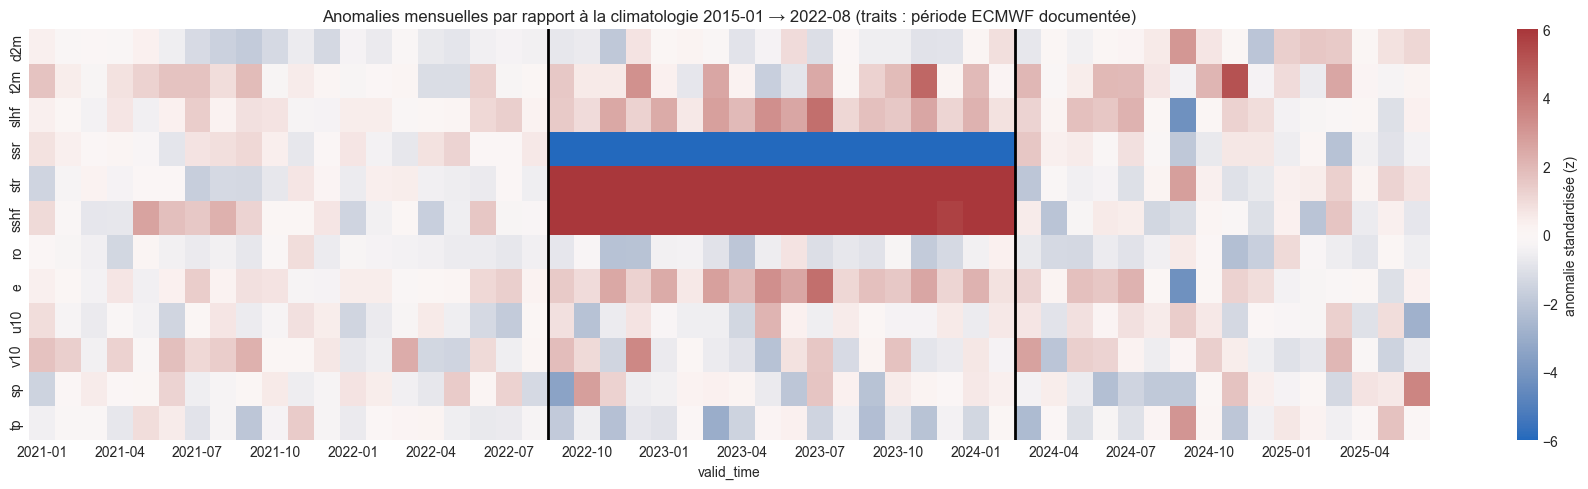

In [13]:
regional_raw = regional_series(conv, BASE)
ref = regional_raw.loc[REF_START:REF_END]
clim_med = ref.groupby(ref.index.month).median()          # climatologie robuste de référence (période saine)
clim_std = ref.groupby(ref.index.month).std()

mo = regional_raw.index.month
z_anom = (regional_raw - clim_med.loc[mo].values) / clim_std.loc[mo].values   # anomalie standardisée par rapport au mois calendaire

window = z_anom.loc["2021-01-01":"2025-06-01"]
x0, x1 = int((window.index < ANOMALY_START).sum()), int((window.index <= ANOMALY_END).sum())
window = window.set_axis(window.index.strftime("%Y-%m"))
plt.figure(figsize=(18, 5))
sns.heatmap(window.T, cmap="vlag", center=0, vmin=-6, vmax=6, cbar_kws={"label": "anomalie standardisée (z)"}, xticklabels=3)
plt.axvline(x0, color="k", lw=2); plt.axvline(x1, color="k", lw=2)
plt.title("Anomalies mensuelles par rapport à la climatologie 2015-01 → 2022-08 (traits : période ECMWF documentée)")
plt.tight_layout(); plt.show()

In [14]:
documented = (regional_raw.index >= ANOMALY_START) & (regional_raw.index <= ANOMALY_END)
ratio_ssr = regional_raw["ssr"] / clim_med.loc[mo, "ssr"].values       # ssr : variable positive, très régulière en Algérie
detected = ratio_ssr < 0.75

print("Mois détectés (ssr < 75 % de sa climatologie) :", [d.strftime("%Y-%m") for d in ratio_ssr.index[detected]])
print(f"Recouvrement avec la période documentée : {int((detected & documented).sum())}/{int(documented.sum())} mois documentés détectés, "
      f"{int((detected & ~documented).sum())} détection(s) hors période")

summary = pd.DataFrame({
    "|z| moyen période documentée": z_anom[documented].abs().mean(),
    "|z| moyen hors période": z_anom[~documented].abs().mean()}).round(2)
summary["accumulée ?"] = [v in ACCUM for v in summary.index]
display(summary)

ANOMALY_PRESENT = bool(detected[documented].mean() > 0.5)
print("Anomalie présente dans ce fichier :", ANOMALY_PRESENT)

Mois détectés (ssr < 75 % de sa climatologie) : ['2022-09', '2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02']
Recouvrement avec la période documentée : 18/18 mois documentés détectés, 0 détection(s) hors période


,|z| moyen période documentée,|z| moyen hors période,accumulée ?
d2m,0.65,0.76,False
t2m,1.38,0.84,False
slhf,1.94,0.82,True
ssr,26.72,0.80,True
str,15.87,0.81,True
sshf,12.51,0.78,True
ro,0.97,0.72,True
e,1.94,0.82,True
u10,0.72,0.79,False
v10,1.13,0.80,False


Anomalie présente dans ce fichier : True


**Estimation du facteur.** Pour chaque variable accumulée, facteur = Σ climatologie / Σ valeur observée sur les 18 mois (rapport de sommes, plus stable qu'une moyenne de rapports). `ssr` est la référence la plus fiable (rayonnement solaire positif et très régulier en Algérie) ; `tp` et `ro` sont trop variables d'une année à l'autre pour estimer un facteur seuls. Comme ECMWF indique un même défaut de traitement pour toutes les variables accumulées, on applique **un facteur unique** estimé sur `ssr` et on vérifie sa cohérence avec `str`, `sshf`, `slhf`.

In [15]:
if ANOMALY_PRESENT:
    k_by_var = {}
    for v in ACCUM:
        exp_ = clim_med.loc[mo[documented], v].values
        obs_ = regional_raw.loc[documented, v].values
        k_by_var[v] = float(np.sum(np.abs(exp_)) / np.sum(np.abs(obs_)))
    display(pd.Series(k_by_var, name="facteur estimé (clim / observé)").round(3).to_frame().T)

    k_ssr = k_by_var["ssr"]
    K_FACTOR = 2.0 if abs(k_ssr - 2.0) <= 0.15 else k_ssr      # facteur 2 retenu si l'estimation le confirme
    print(f"Facteur estimé sur ssr : {k_ssr:.3f} → facteur appliqué K = {K_FACTOR:.3f}")
    stable = ["ssr","str","sshf","slhf"]
    print("Facteurs des variables énergétiques :", {v: round(k_by_var[v], 2) for v in stable})
else:
    k_by_var, K_FACTOR = {}, 1.0
    print("Pas d'anomalie détectée : aucune correction (fichier probablement déjà re-téléchargé).")

,slhf,ssr,str,sshf,ro,e,tp
facteur estimé (clim / observé),2.479,1.872,2.061,2.046,2.639,2.478,2.758


Facteur estimé sur ssr : 1.872 → facteur appliqué K = 2.000
Facteurs des variables énergétiques : {'ssr': 1.87, 'str': 2.06, 'sshf': 2.05, 'slhf': 2.48}


In [16]:
affected_times = regional_raw.index[documented] if ANOMALY_PRESENT else pd.DatetimeIndex([])
df["anomaly_corrected"] = df["time"].isin(affected_times).astype(int)
df_before_fix = df[ACCUM + ["time","year","lat"]].copy()     # copie pour la comparaison avant/après

if ANOMALY_PRESENT:
    m = df["anomaly_corrected"] == 1
    for v in ACCUM:
        df.loc[m, v] = df.loc[m, v] * K_FACTOR
    conv_fixed = conv.copy()
    for v in ACCUM:
        conv_fixed[v] = conv[v].where(~conv.valid_time.isin(affected_times), conv[v] * K_FACTOR)
else:
    conv_fixed = conv

print("Lignes corrigées :", int(df["anomaly_corrected"].sum()), f"({df['anomaly_corrected'].mean()*100:.1f} %)")
log_step("3. Incohérences 2022-2024", f"variables accumulées × {K_FACTOR:.3f} sur {len(affected_times)} mois" if ANOMALY_PRESENT else "aucune",
         variables=ACCUM if ANOMALY_PRESENT else [], periode=[str(ANOMALY_START.date()), str(ANOMALY_END.date())],
         facteurs_estimes={k: round(v, 3) for k, v in k_by_var.items()}, source="ECMWF known issue (forum topic 2370)")

Lignes corrigées : 97632 (12.8 %)
[LOG] 3. Incohérences 2022-2024 → variables accumulées × 2.000 sur 18 mois


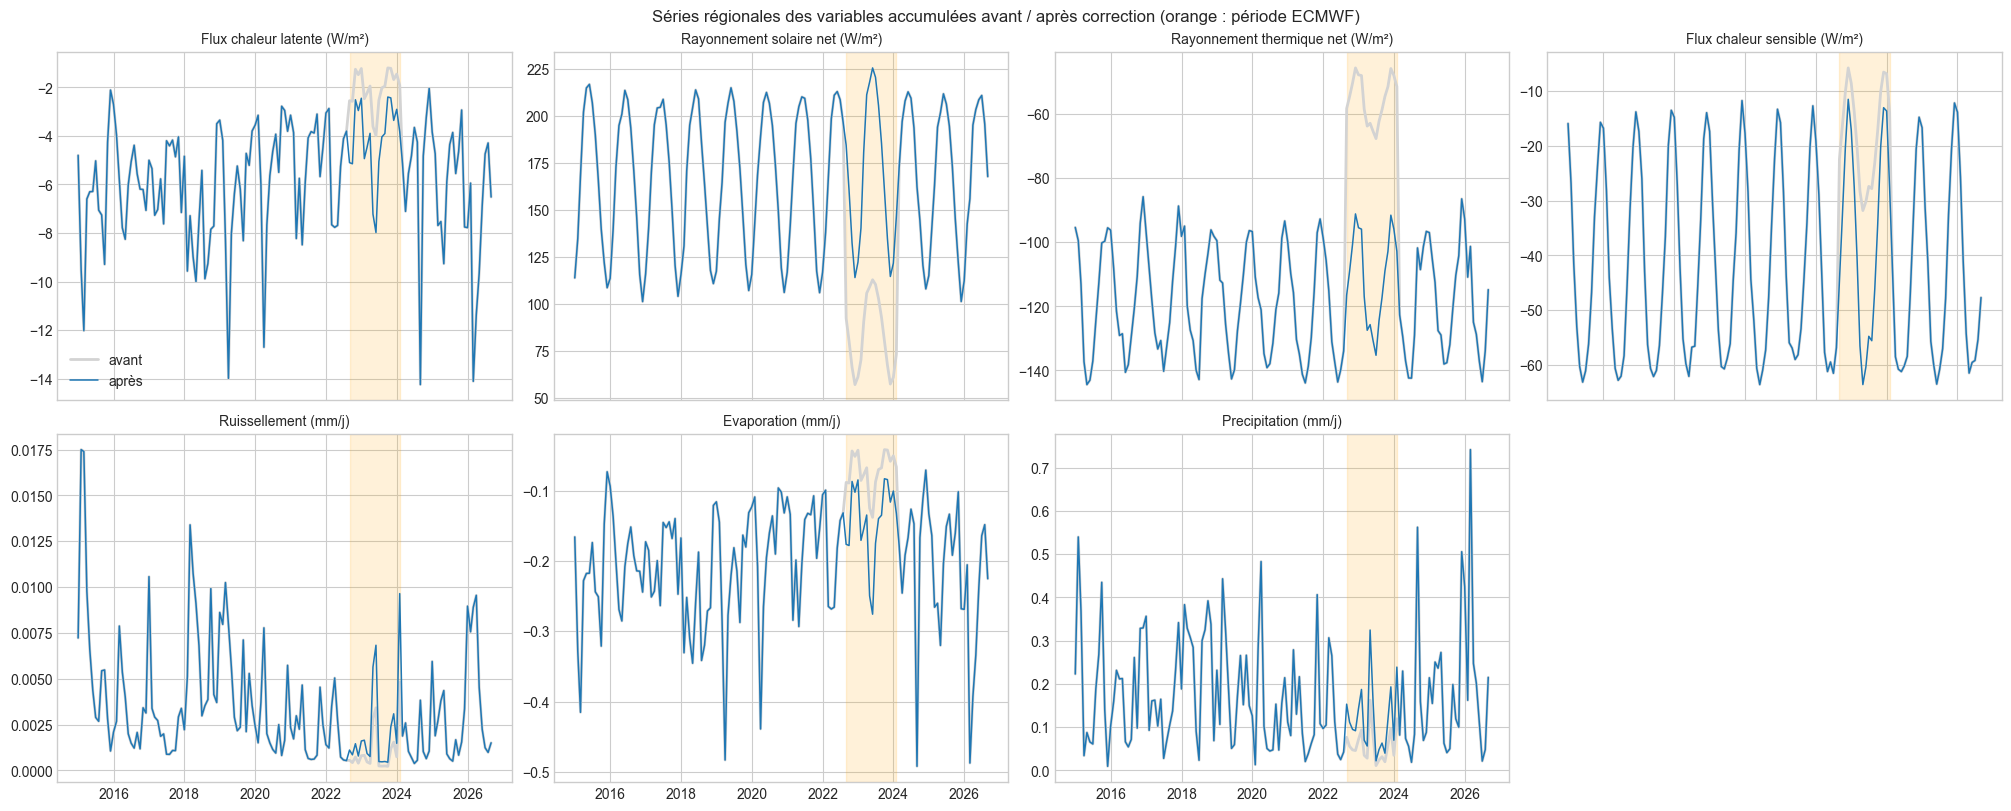

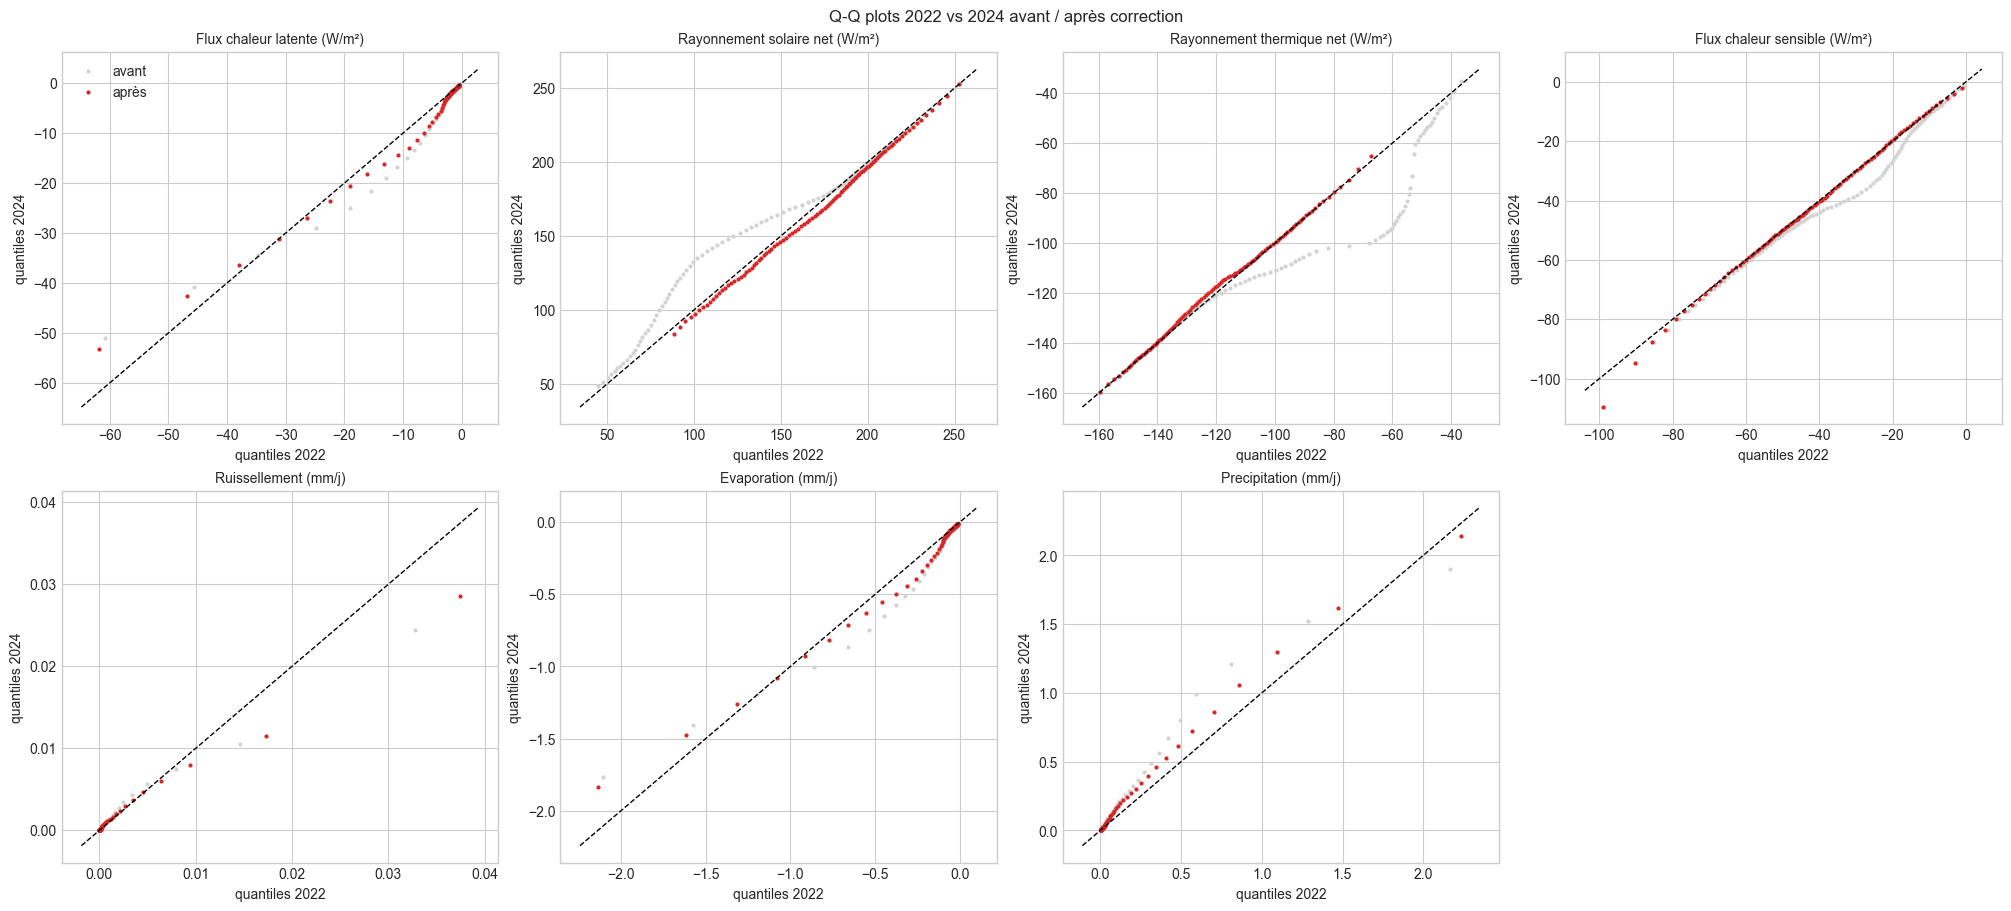

,|z| période avant,|z| période après,|z| hors période
slhf,1.94,0.81,0.82
ssr,26.72,3.91,0.80
str,15.87,0.99,0.81
sshf,12.51,1.01,0.78
ro,0.97,0.85,0.72
e,1.94,0.81,0.82
tp,1.14,1.11,0.82


In [17]:
regional_fix = regional_series(conv_fixed, BASE)
fig, axes = plt.subplots(2, 4, figsize=(20, 8), constrained_layout=True, sharex=True)
for ax, v in zip(axes.flat, ACCUM):
    ax.plot(regional_raw.index, regional_raw[v], color="lightgrey", lw=2, label="avant")
    ax.plot(regional_fix.index, regional_fix[v], color="tab:blue", lw=1.1, label="après")
    ax.axvspan(ANOMALY_START, ANOMALY_END, color="orange", alpha=.15)
    ax.set_title(LABELS[v], fontsize=10)
axes.flat[0].legend(); axes.flat[-1].set_visible(False)
fig.suptitle("Séries régionales des variables accumulées avant / après correction (orange : période ECMWF)"); plt.show()

qs = np.linspace(0.01, 0.99, 99)
fig, axes = plt.subplots(2, 4, figsize=(20, 9), constrained_layout=True)
for ax, v in zip(axes.flat, ACCUM):
    for src, col, lab in [(df_before_fix, "lightgrey", "avant"), (df, "tab:red", "après")]:
        a = src.loc[src["year"] == 2022, v]; b = src.loc[src["year"] == 2024, v]
        ax.plot(np.quantile(a, qs), np.quantile(b, qs), ".", ms=4, color=col, label=lab)
    lim = ax.get_xlim(); ax.plot(lim, lim, "k--", lw=1)
    ax.set_title(LABELS[v], fontsize=10); ax.set_xlabel("quantiles 2022"); ax.set_ylabel("quantiles 2024")
axes.flat[0].legend(); axes.flat[-1].set_visible(False)
fig.suptitle("Q-Q plots 2022 vs 2024 avant / après correction"); plt.show()

# Contrôle quantitatif : après correction, les mois corrigés doivent redevenir comparables à la climatologie
z_after = (regional_fix - clim_med.loc[mo].values) / clim_std.loc[mo].values
check = pd.DataFrame({"|z| période avant": z_anom.loc[documented, ACCUM].abs().mean(),
                      "|z| période après": z_after.loc[documented, ACCUM].abs().mean(),
                      "|z| hors période": z_anom.loc[~documented, ACCUM].abs().mean()}).round(2)
display(check)

Les années 2022 et 2024 n'ont pas à être identiques : après correction, il reste des écarts réels (ex. 2024 plus chaude et plus humide sur certaines régions, visibles aussi sur `t2m` et `d2m` qui ne sont pas touchées par le bug). On ne corrige que l'artefact documenté, pas la variabilité climatique.

## 4. Valeurs aberrantes et distributions asymétriques

**Constat EDA :** `slhf`/`e` (skew −4,2 ; 16,5 % d'outliers IQR), `tp` (skew 5,8 ; 15 %), `ro` (skew 45 ; 16 %) ont une énorme proportion de « outliers ». Les autres variables ont < 2 % d'outliers.

**Analyse :** pour ces variables, une proportion de 15-16 % n'est pas compatible avec des erreurs : c'est la **forme de la distribution** (intermittence de la pluie, du ruissellement et de l'évaporation en zone aride : la plupart des mois ≈ 0, quelques mois humides). Les valeurs extrêmes sont des événements réels (épisodes pluvieux du Nord, crues). Les supprimer ou les écrêter effacerait précisément l'information climatique utile et casserait la grille spatio-temporelle (une ligne supprimée = un trou dans la série d'une cellule, et une target M+1 impossible à construire).

**Méthode (cours 04 « Handling outliers ») :**
1. **contrôle combiné machine + expert** : règles de plausibilité physique ; une violation = erreur → traitée comme valeur manquante ;
2. **transformation des données** (log) pour les variables très asymétriques : `tp`, `ro` → `log1p(x)` ; `slhf`, `e` (≤ 0) → `−log1p(−x)` (log signé) ;
3. variables faiblement concernées (`d2m`, `sshf`, `str`, `u10`, `v10`, `sp`) : **conservées telles quelles** (extrêmes physiques : cellules d'altitude pour `sp`, flux sensible positif l'hiver…) ;
4. le Random Forest (modèle robuste aux outliers, cours 04) bénéficiera en plus des données non transformées si besoin.

Le log est une **fonction fixe, sans paramètre appris** : il peut être appliqué avant le split sans aucune fuite.

In [18]:
PLAUSIBILITY = {                       # bornes physiques larges (unités d'analyse)
    "t2m": (-40, 60), "d2m": (-60, 40), "sp": (500, 1100),
    "ssr": (0, 450), "tp": (0, None), "ro": (0, None),
    "e": (None, 1.0), "u10": (-40, 40), "v10": (-40, 40)}
viol = {}
for v, (lo_, hi_) in PLAUSIBILITY.items():
    bad = pd.Series(False, index=df.index)
    if lo_ is not None: bad |= df[v] < lo_
    if hi_ is not None: bad |= df[v] > hi_
    viol[v] = bad
viol["d2m > t2m"] = df["d2m"] > df["t2m"] + 0.5       # le point de rosée ne peut pas dépasser la température (marge 0,5 °C)
viol_tab = pd.Series({k: int(b.sum()) for k, b in viol.items()}, name="violations")
display(viol_tab.to_frame().T)

n_viol = int(viol_tab.sum())
if n_viol:
    # valeurs physiquement impossibles → NaN → même imputation spatiale que la section 2
    for v, bad in viol.items():
        col = "d2m" if v == "d2m > t2m" else v
        df.loc[bad, col] = np.nan
    for v in BASE:
        if df[v].isna().any():   # interpolation temporelle dans la série de chaque cellule (df est trié par mois)
            df[v] = df.groupby("cell")[v].transform(lambda s: s.interpolate(limit_direction="both"))
assert not df[BASE].isna().any().any()
log_step("4a. Plausibilité physique", f"{n_viol} valeur(s) impossible(s) traitée(s) comme manquantes", violations=viol_tab.to_dict())

,t2m,d2m,sp,ssr,tp,ro,e,u10,v10,d2m > t2m
violations,0,0,0,0,0,0,0,0,0,0


[LOG] 4a. Plausibilité physique → 0 valeur(s) impossible(s) traitée(s) comme manquantes


In [19]:
def outlier_table(d, cols):
    rows = []
    for v in cols:
        x = d[v].dropna().values
        q1, q3 = np.percentile(x, [25, 75]); i = q3 - q1
        iqr_n = int(((x < q1 - 1.5*i) | (x > q3 + 1.5*i)).sum())
        z = (x - x.mean()) / x.std(ddof=1)
        rows.append({"variable": v, "% IQR": 100*iqr_n/len(x), "% Z>3": 100*int((np.abs(z) > 3).sum())/len(x),
                     "skew": stats.skew(x)})
    return pd.DataFrame(rows).set_index("variable")

out_before = outlier_table(df, INPUT_VARS)
display(out_before.round(2))

,% IQR,% Z>3,skew
variable,,,
d2m,1.15,0.52,0.290000
slhf,16.79,2.78,-4.140000
ssr,0.00,0.00,-0.120000
str,0.08,0.05,0.340000
sshf,0.95,0.66,-0.390000
ro,16.31,0.67,43.099998
e,16.79,2.78,-4.140000
u10,0.71,0.40,0.080000
v10,1.08,0.22,-0.240000


avant                   après              transformation
          % IQR % Z>3       skew  % IQR % Z>3   skew               
variable                                                           
d2m        1.15  0.52   0.290000   1.15  0.52   0.29         aucune
slhf      16.79  2.78  -4.140000  10.58  1.32  -1.43   signed_log1p
ssr        0.00  0.00  -0.120000   0.00  0.00  -0.12         aucune
str        0.08  0.05   0.340000   0.08  0.05   0.34         aucune
sshf       0.95  0.66  -0.390000   0.95  0.66  -0.39         aucune
ro        16.31  0.67  43.099998  16.31  0.91  20.51          log1p
e         16.79  2.78  -4.140000  16.24  3.15  -2.87   signed_log1p
u10        0.71  0.40   0.080000   0.71  0.40   0.08         aucune
v10        1.08  0.22  -0.240000   1.08  0.22  -0.24         aucune
sp         1.85  0.54  -0.840000   1.85  0.54  -0.84         aucune
tp        15.16  2.35   5.740000  14.44  3.06   3.30          log1p

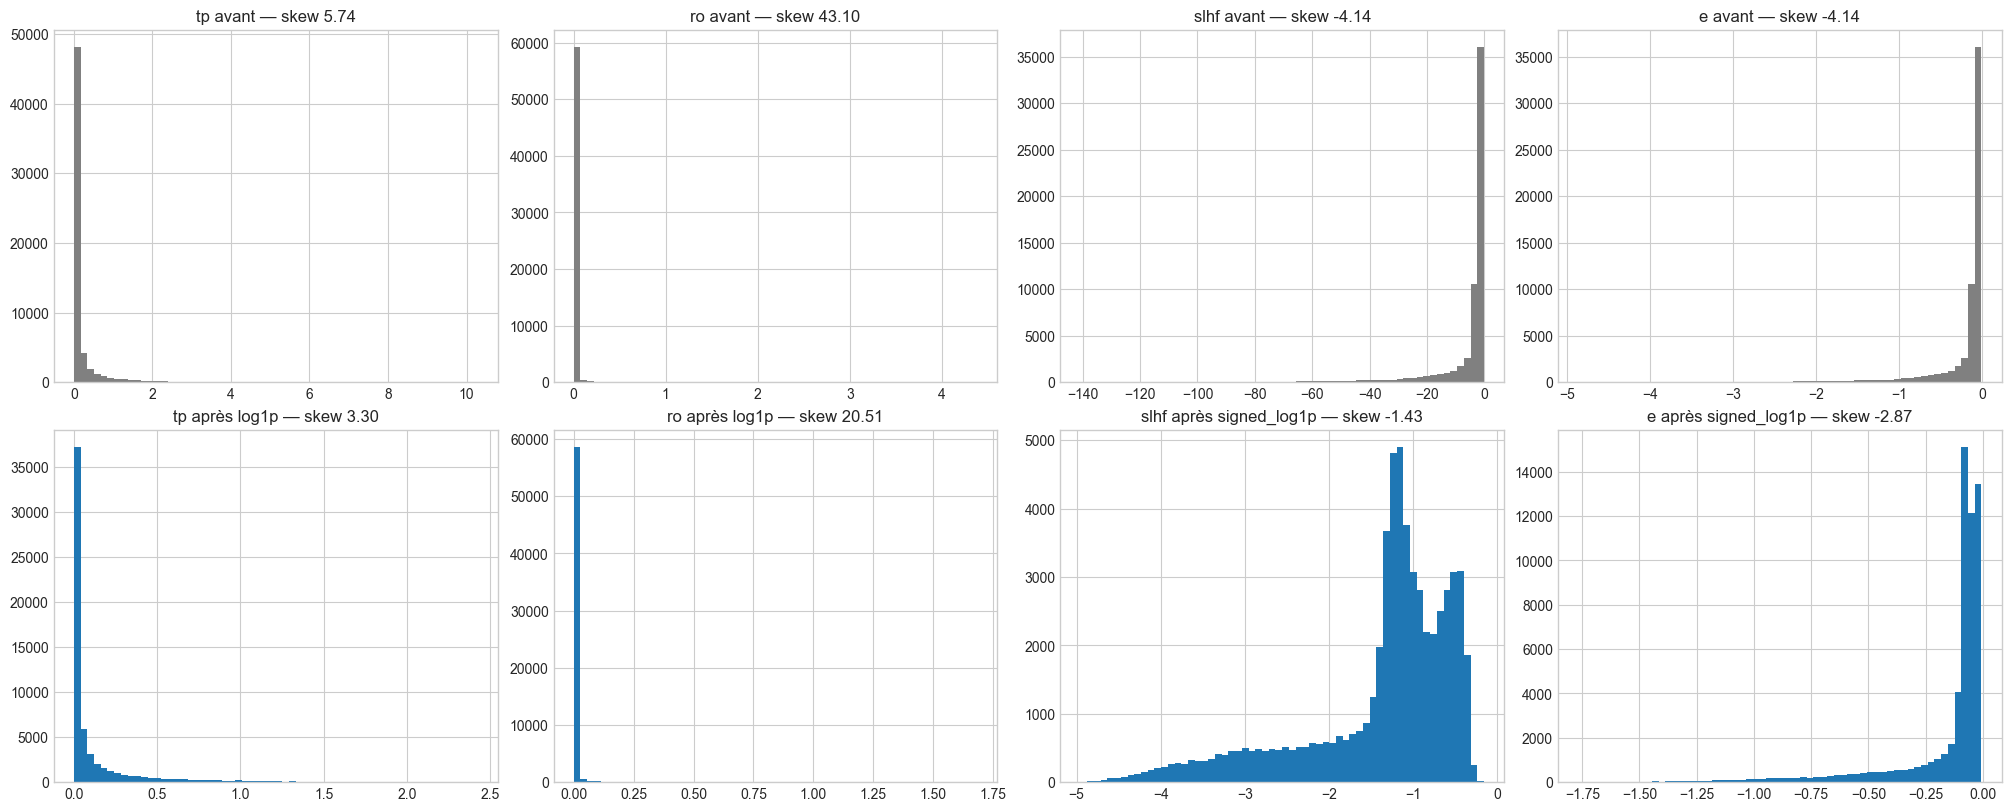

[LOG] 4b. Outliers / asymétrie → aucune suppression ; transformation log des variables intermittentes


In [20]:
def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

TRANSFORMS = {"tp": "log1p", "ro": "log1p", "slhf": "signed_log1p", "e": "signed_log1p"}
df_phys = df[INPUT_VARS + ["t2m"]].copy()          # valeurs physiques corrigées, avant transformation (pour l'export non transformé et les graphiques)
for v, f in TRANSFORMS.items():
    df[v] = np.log1p(df[v]) if f == "log1p" else signed_log1p(df[v])

out_after = outlier_table(df, INPUT_VARS)
comp = pd.concat({"avant": out_before, "après": out_after}, axis=1).round(2)
comp["transformation"] = [TRANSFORMS.get(v, "aucune") for v in comp.index]
display(comp)

SAMPLE_IDX = df.sample(min(60_000, len(df)), random_state=SEED).index       # échantillon pour les graphiques uniquement
fig, axes = plt.subplots(2, len(TRANSFORMS), figsize=(20, 8), constrained_layout=True)
for j, v in enumerate(TRANSFORMS):
    axes[0, j].hist(df_phys.loc[SAMPLE_IDX, v], bins=60, color="grey")
    axes[0, j].set_title(f"{v} avant — skew {out_before.loc[v, 'skew']:.2f}")
    axes[1, j].hist(df.loc[SAMPLE_IDX, v], bins=60, color="tab:blue")
    axes[1, j].set_title(f"{v} après {TRANSFORMS[v]} — skew {out_after.loc[v, 'skew']:.2f}")
plt.show()

assert len(df) == N * T, "Aucune ligne ne doit être supprimée par le traitement des outliers"
log_step("4b. Outliers / asymétrie", "aucune suppression ; transformation log des variables intermittentes",
         transformations=TRANSFORMS, skew_avant=out_before["skew"].round(2).to_dict(), skew_apres=out_after["skew"].round(2).to_dict())

Remarque : `ro` reste très asymétrique même après le log (≈ 19 % de zéros exacts : une masse en 0 ne peut pas être « symétrisée » par une transformation monotone). Son sort est décidé en sections 5 et 8 (faible variance + redondance avec `tp`).

## 5. Variables à faible variabilité

**Constat EDA :** variance < 0,01 en unités d'analyse : `ro` seulement ; variance après Min-Max < 0,01 : `slhf`, `ro`, `e`, `tp` ; `sp` : < 5 % de variance temporelle.

**Analyse :**
- le seuil 0,01 du cours dépend des unités ; on l'applique donc à la variance **après normalisation Min-Max** (calculée sur la période Train) ;
- une faible variance Min-Max peut venir d'une vraie absence d'information **ou** d'une queue lourde qui écrase toutes les valeurs près d'une borne : c'est pour cela que le critère est réévalué **après** la transformation log de la section 4 ;
- `sp` varie peu dans le temps mais énormément dans l'espace (788 → 1037 hPa) : c'est un **proxy de l'altitude**, déterminant pour la température (gradient ≈ −6,5 °C/km). Elle est conservée.

**Décision :** une variable n'est supprimée **sur ce seul critère** que si elle est quasi constante (variance Min-Max < 10⁻⁴). Les autres variables sous 0,01 sont **marquées** (`LOWVAR_FLAG`) : en cas de redondance (section 8), la variable marquée est éliminée en priorité.

In [21]:
last_train_month = TEST_START - pd.DateOffset(months=2)      # dernier mois M dont la cible M+1 < TEST_START
period_train = df["time"] <= last_train_month

def variance_table(d, phys, mask):
    rows = []
    for v in INPUT_VARS:
        x, xp = d.loc[mask, v], phys.loc[mask, v]
        mm  = (x - x.min()) / (x.max() - x.min())
        mmp = (xp - xp.min()) / (xp.max() - xp.min())
        rows.append({"variable": v, "variance (unités)": xp.var(), "Min-Max avant transfo": mmp.var(),
                     "Min-Max après transfo": mm.var(), "valeurs uniques": x.nunique()})
    return pd.DataFrame(rows).set_index("variable")

var_tab = variance_table(df, df_phys, period_train)
grid_var_time = {v: float(conv_fixed[v].where(domain).var("valid_time").mean()) for v in INPUT_VARS}
var_tab["% variance temporelle"] = [100 * grid_var_time[v] / df_phys.loc[period_train, v].var(ddof=0) for v in INPUT_VARS]
var_tab["< 0.01 après transfo"] = var_tab["Min-Max après transfo"] < LOWVAR_THRESHOLD
print(var_tab.to_string(float_format=lambda x: f"{x:.4g}"))

LOWVAR_FLAG = var_tab.index[var_tab["< 0.01 après transfo"]].tolist()
DROP_LOWVAR = var_tab.index[var_tab["Min-Max après transfo"] < 1e-4].tolist()
print("\nMarquées faible variance (prioritaires en cas de redondance) :", LOWVAR_FLAG)
print("Supprimées car quasi constantes :", DROP_LOWVAR)
assert (df.loc[period_train, INPUT_VARS].std() > 0).all(), "Une variable est constante"
log_step("5. Faible variabilité", f"supprimées : {DROP_LOWVAR or 'aucune'} ; marquées : {LOWVAR_FLAG}",
         variance_minmax_apres=var_tab["Min-Max après transfo"].round(5).to_dict(), sp="conservée (proxy altitude)")

          variance (unités)  Min-Max avant transfo  Min-Max après transfo  valeurs uniques  % variance temporelle  < 0.01 après transfo
variable                                                                                                                               
d2m                   23.25                0.01489                0.01489           104307                  66.74                 False
slhf                  142.9               0.004338                0.03125           432736                  29.29                 False
ssr                    1811                0.02933                0.02933           559566                  82.43                 False
str                   508.7                0.02849                0.02849           550321                  61.41                 False
sshf                  473.6               0.009709               0.009709           567038                  77.53                  True
ro                 0.001648              4.583e-

## 6. Feature extraction

Features retenues (cours 05 « derived features » et « mathematical functions ») :

| Feature | Construction | Justification |
|---|---|---|
| `wind10_speed` | $\sqrt{u_{10}^2+v_{10}^2}$ | intensité du vent (le mélange turbulent dépend de la vitesse, pas du signe des composantes) ; déjà calculée dans l'EDA |
| `month_sin`, `month_cos` | $\sin(2\pi m/12)$, $\cos(2\pi m/12)$ | encodage **cyclique** : décembre et janvier sont voisins. Avec `month` brut, KNN/SVM verraient une distance de 11 entre décembre et janvier. `month` est tout de même gardé (imposé par le support) |

Non retenues (justification) :
- **ACP** : 11-13 features seulement, et le RF / l'interprétation des modèles demandent les variables originales ; l'ACP est plutôt utile pour la visualisation ;
- **lat / lon** et **t2m du mois M** : non prévus dans la liste des features du support de projet. `t2m(M)` serait un prédicteur très fort (persistance) mais changerait la nature du problème ; à valider avec l'enseignante. Les interrupteurs `ADD_LATLON` / `ADD_T2M_CURRENT` permettent de les tester sans modifier le reste.

In [22]:
ADD_LATLON = False
ADD_T2M_CURRENT = False

df["wind10_speed"] = np.hypot(df["u10"], df["v10"])
df_phys["wind10_speed"] = df["wind10_speed"]
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
df["t2m_current"] = df_phys["t2m"]

CANDIDATES = [v for v in INPUT_VARS if v not in DROP_LOWVAR] + ["wind10_speed"]      # variables physiques soumises à la sélection
CALENDAR = ["month", "year", "month_sin", "month_cos"]
EXTRA = (["lat", "lon"] if ADD_LATLON else []) + (["t2m_current"] if ADD_T2M_CURRENT else [])
print("Candidates physiques :", CANDIDATES); print("Calendaires :", CALENDAR); print("Optionnelles activées :", EXTRA)
log_step("6. Feature extraction", "ajout wind10_speed, month_sin, month_cos", optionnelles=EXTRA)

Candidates physiques : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp', 'wind10_speed']
Calendaires : ['month', 'year', 'month_sin', 'month_cos']
Optionnelles activées : []
[LOG] 6. Feature extraction → ajout wind10_speed, month_sin, month_cos


## 7. Construction de la Target Feature : température à M+1

Pour chaque cellule, la cible de la ligne (cellule, M) est `t2m` de la **même cellule** au mois **M+1** : tri par (`cell`, `time`) puis `shift(-1)` **à l'intérieur de chaque cellule** (jamais à travers deux cellules). On vérifie que le mois suivant est bien M+1 (série sans trou) et on contrôle l'alignement directement sur la grille xarray. Le dernier mois (pas de M+1 disponible) est retiré : on perd exactement 1 ligne par cellule.

In [23]:
df = df.sort_values(["cell", "time"]).reset_index(drop=True)
g = df.groupby("cell", sort=False)
df["t2m_next"] = g["t2m_current"].shift(-1)
df["target_time"] = g["time"].shift(-1)

ok = df["target_time"].notna()
gap_months = (df.loc[ok, "target_time"].dt.year * 12 + df.loc[ok, "target_time"].dt.month) - (df.loc[ok, "year"] * 12 + df.loc[ok, "month"])
assert (gap_months == 1).all(), "La cible n'est pas toujours le mois suivant"

# Contrôle d'alignement sur la grille d'origine (20 lignes tirées au hasard)
for _, r in df.loc[ok].sample(20, random_state=SEED).iterrows():
    ref_val = float(conv_fixed["t2m"].sel(valid_time=r["target_time"], latitude=r["lat"], longitude=r["lon"]))
    assert np.isclose(ref_val, r["t2m_next"]), "Désalignement M / M+1"

n_last = int((~ok).sum())
assert n_last == N and (df.loc[~ok, "time"] == df["time"].max()).all()
df = df.loc[ok].reset_index(drop=True)
print(f"Lignes sans cible (dernier mois {pd.Timestamp(df['target_time'].max()).date()} exclu côté features) : {n_last} = 1 par cellule")
print("Période des features :", df["time"].min().date(), "→", df["time"].max().date())
print("Période de la cible  :", df["target_time"].min().date(), "→", df["target_time"].max().date())
display(df[["cell","lat","lon","time","t2m_current","target_time","t2m_next"]].head(4))
log_step("7. Target", "t2m(M+1) par cellule ; dernier mois retiré", lignes_retirees=n_last)

Lignes sans cible (dernier mois 2026-09-01 exclu côté features) : 5424 = 1 par cellule
Période des features : 2015-01-01 → 2026-08-01
Période de la cible  : 2015-02-01 → 2026-09-01


,cell,lat,lon,time,t2m_current,target_time,t2m_next
0,0,37.05,6.25,2015-01-01,9.714508,2015-02-01,8.681549
1,0,37.05,6.25,2015-02-01,8.681549,2015-03-01,11.495758
2,0,37.05,6.25,2015-03-01,11.495758,2015-04-01,14.925934
3,0,37.05,6.25,2015-04-01,14.925934,2015-05-01,18.871735


[LOG] 7. Target → t2m(M+1) par cellule ; dernier mois retiré


## 8. Corrélation et sélection des features (sur Train uniquement)

**Choix de la formule :** l'EDA a montré qu'aucune variable n'est normale (test de Shapiro) → **Spearman** (cours 03 : distributions non normales, relations monotones non linéaires, outliers). Spearman n'est pas modifié par les transformations monotones (log) de la section 4 ; il est en revanche modifié par la correction 2022-2024, d'où son recalcul ici.

**Sans fuite :** matrice et corrélations avec la cible calculées sur les seules lignes du Train.

**Règle de décision pour chaque paire |ρ| > 0,90 (cours 04) :** on ne supprime pas aveuglément ; on garde la variable la plus utile :
1. si une seule des deux est marquée faible variance (section 5) → on retire celle-là ;
2. sinon on retire celle qui a la plus faible |ρ| avec la cible t2m(M+1) (méthode filtre CFS du cours 05) ;
3. en cas d'égalité (cas `slhf`/`e`, liés par la relation physique exacte LE = L_v·E), on retire `e` et on garde `slhf`, en W/m² comme les autres flux du bilan d'énergie.

`MANUAL_KEEP` permet de forcer la conservation d'une variable si l'enseignante le demande.

Variables normales (Shapiro, p > 0.05) : aucune → Spearman


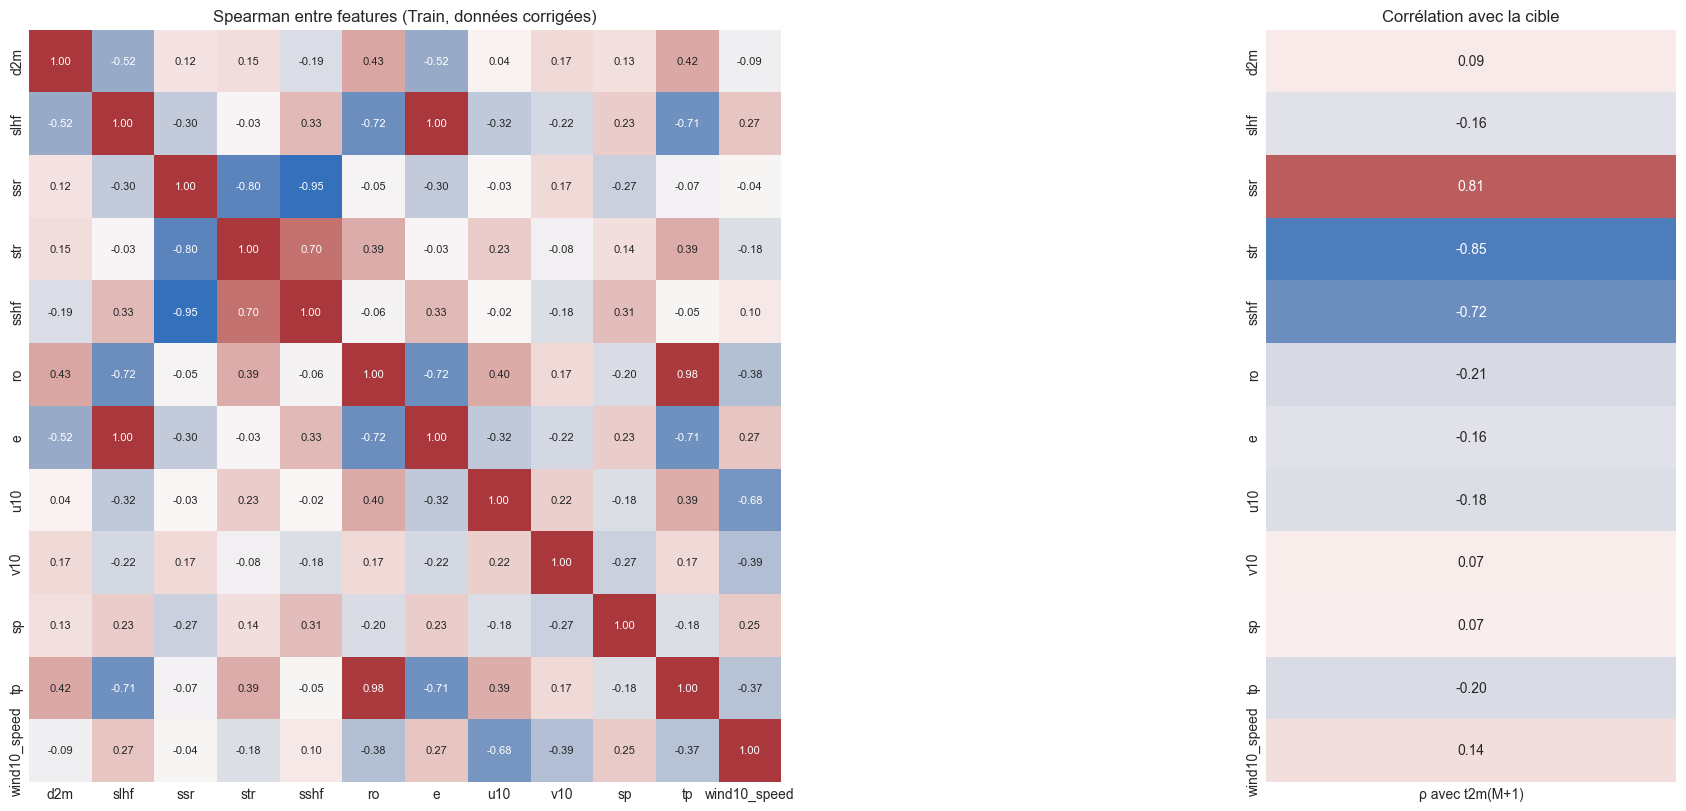

In [24]:
train_rows = df["target_time"] < TEST_START
tr = df.loc[train_rows]

rng_idx = tr.sample(min(5000, len(tr)), random_state=SEED).index
IS_NORMAL = {v: stats.shapiro(tr.loc[rng_idx, v]).pvalue > 0.05 for v in CANDIDATES}
print("Variables normales (Shapiro, p > 0.05) :", [v for v, n_ in IS_NORMAL.items() if n_] or "aucune", "→ Spearman")

corr_s = tr[CANDIDATES].rank().corr()                           # Spearman = Pearson sur les rangs
corr_target = tr[CANDIDATES].corrwith(tr["t2m_next"], method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(21, 8), gridspec_kw={"width_ratios": [4, 1]}, constrained_layout=True)
sns.heatmap(corr_s, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, cbar=False, ax=axes[0], annot_kws={"size": 8})
axes[0].set_title("Spearman entre features (Train, données corrigées)")
sns.heatmap(corr_target.to_frame("ρ avec t2m(M+1)"), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, cbar=False, ax=axes[1])
axes[1].set_title("Corrélation avec la cible")
plt.show()

In [25]:
MANUAL_KEEP = set()
TIE_DROP_PRIORITY = ["e", "ro"]          # en cas d'égalité stricte, retirer d'abord ces variables

pairs = (corr_s.where(np.triu(np.ones(corr_s.shape, bool), 1)).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "var1", "level_1": "var2"}))
high = pairs[pairs["rho"].abs() > CORR_THRESHOLD].sort_values("rho", key=abs, ascending=False)

kept, decisions = list(CANDIDATES), []
for _, p in high.iterrows():
    a, b = p["var1"], p["var2"]
    if a not in kept or b not in kept:
        decisions.append({**p, "retirée": "—", "raison": "déjà résolue par une paire précédente"}); continue
    ca, cb = abs(corr_target[a]), abs(corr_target[b])
    if (a in LOWVAR_FLAG) != (b in LOWVAR_FLAG):
        drop, why = (a if a in LOWVAR_FLAG else b), "faible variance (section 5) + redondante"
    elif abs(ca - cb) > 0.01:
        drop, why = (a if ca < cb else b), f"|ρ cible| plus faible ({min(ca, cb):.3f} < {max(ca, cb):.3f})"
    else:
        drop = next((x for x in TIE_DROP_PRIORITY if x in (a, b)), b)
        why = "information identique (égalité) → priorité physique"
    if drop in MANUAL_KEEP:
        decisions.append({**p, "retirée": "—", "raison": "conservée manuellement"}); continue
    kept.remove(drop)
    decisions.append({**p, "retirée": drop, "raison": why})

dec_tab = pd.DataFrame(decisions)
dec_tab["ρ cible var1"] = [corr_target[a] for a in dec_tab["var1"]] if len(dec_tab) else []
dec_tab["ρ cible var2"] = [corr_target[b] for b in dec_tab["var2"]] if len(dec_tab) else []
display(dec_tab.round(3))

DROP_CORR = [d["retirée"] for d in decisions if d["retirée"] != "—"]
PHYS_FEATURES = kept
FEATURES = PHYS_FEATURES + CALENDAR + EXTRA

rem = corr_s.loc[PHYS_FEATURES, PHYS_FEATURES].abs().where(~np.eye(len(PHYS_FEATURES), dtype=bool))
assert (rem.max().max() <= CORR_THRESHOLD) or (MANUAL_KEEP & set(PHYS_FEATURES)), "Redondance résiduelle"
print("Retirées pour redondance :", DROP_CORR)
print(f"Features finales ({len(FEATURES)}) :", FEATURES)
log_step("8. Corrélation / sélection", f"retirées : {DROP_CORR}", methode="Spearman sur Train",
         paires=[{k: (round(v, 3) if isinstance(v, float) else v) for k, v in d.items()} for d in decisions],
         rho_cible=corr_target.round(3).to_dict(), features_finales=FEATURES)

,var1,var2,rho,retirée,raison,ρ cible var1,ρ cible var2
0,slhf,e,1.000,e,information identique (égalité) → priorité phy...,-0.157,-0.157
1,ro,tp,0.980,ro,faible variance (section 5) + redondante,-0.209,-0.203
2,ssr,sshf,-0.948,sshf,faible variance (section 5) + redondante,0.811,-0.719


Retirées pour redondance : ['e', 'ro', 'sshf']
Features finales (13) : ['d2m', 'slhf', 'ssr', 'str', 'u10', 'v10', 'sp', 'tp', 'wind10_speed', 'month', 'year', 'month_sin', 'month_cos']
[LOG] 8. Corrélation / sélection → retirées : ['e', 'ro', 'sshf']


**Lecture physique des paires redondantes** (à reprendre dans le rapport) :
- `slhf` ↔ `e` (ρ = 1) : même grandeur à une constante près (flux de chaleur latente = chaleur latente de vaporisation × évaporation) ; garder les deux double le poids de cette information dans la distance du KNN ;
- `ro` ↔ `tp` : le ruissellement est une réponse aux précipitations ; en zone aride `ro ≈ 0` sauf épisode pluvieux, d'où la relation monotone ; `ro` est en plus la variable à plus faible variance ;
- `ssr` ↔ `sshf` : au Sahara, l'évaporation est quasi nulle, donc le rayonnement absorbé repart surtout en chaleur sensible (bilan d'énergie de surface) ; la plus liée à t2m(M+1) est gardée.

## 9. Discrétisation de la Target Feature

**Méthode imposée par le support :** 3 intervalles de **même largeur** (equal-width, cours 04 : $W = (B-A)/N$).
Elle est adaptée ici : l'EDA n'a trouvé **aucun outlier** sur `t2m` (0 % IQR, 0 % Z-score, skew −0,13), donc le principal défaut de l'equal-width (intervalles dominés par les outliers) ne s'applique pas.

**Sans fuite :** $A$ et $B$ = min et max de t2m(M+1) **sur le Train uniquement**. Les bornes extrêmes sont ensuite ouvertes ($-\infty$, $+\infty$) pour que toute valeur de Test hors de l'étendue du Train soit affectée à la classe extrême la plus proche.

*Rappel :* l'EDA avait calculé les seuils sur tout le dataset (`[0.91, 14.33, 27.74, 41.16]`) — acceptable pour explorer, mais c'est une fuite pour le modèle ; ils sont recalculés ici.

In [26]:
A, B = df.loc[train_rows, "t2m_next"].min(), df.loc[train_rows, "t2m_next"].max()
EDGES_TRAIN = np.linspace(A, B, N_CLASSES + 1)
W = (B - A) / N_CLASSES
BINS = [-np.inf, *EDGES_TRAIN[1:-1], np.inf]
df["classe"] = pd.cut(df["t2m_next"], bins=BINS, labels=CLASS_LABELS, right=True)
df["y"] = df["classe"].cat.codes.astype(int)
assert (df["y"] >= 0).all()

intervals = pd.DataFrame({"classe": CLASS_LABELS, "code": range(N_CLASSES),
                          "borne inf (°C)": EDGES_TRAIN[:-1].round(2), "borne sup (°C)": EDGES_TRAIN[1:].round(2)})
display(intervals)
print(f"Largeur W = ({B:.2f} − {A:.2f}) / {N_CLASSES} = {W:.2f} °C")
outside = df.loc[df["time"] >= TEST_START, "t2m_next"]
print(f"Valeurs de Test hors de [A, B] : {int(((outside < A) | (outside > B)).sum())} "
      f"(< A : {int((outside < A).sum())}, > B : {int((outside > B).sum())})")
display(df.groupby("classe", observed=False)["t2m_next"].agg(["count", "min", "max", "mean"]).round(2))
log_step("9. Discrétisation", "equal-width 3 classes, seuils Train", bornes=EDGES_TRAIN.round(3).tolist(), largeur=round(float(W), 3))

,classe,code,borne inf (°C),borne sup (°C)
0,Froid,0,0.91,14.33
1,Modere,1,14.33,27.74
2,Chaud,2,27.74,41.16


Largeur W = (41.16 − 0.91) / 3 = 13.41 °C
Valeurs de Test hors de [A, B] : 0 (< A : 0, > B : 0)


,count,min,max,mean
classe,,,,
Froid,129447,0.91,14.33,11.17
Modere,327329,14.33,27.74,20.74
Chaud,302584,27.74,41.16,32.98


[LOG] 9. Discrétisation → equal-width 3 classes, seuils Train


## 10. Split Train / Test chronologique

Un split aléatoire mélangerait des mois voisins (fortement autocorrélés) entre Train et Test et permettrait au modèle de « voir le futur » : interdit par le support (*« split in a chronological order »*).

| Ensemble | Mois des features M | Mois de la cible M+1 |
|---|---|---|
| Train | 2015-01 → 2023-11 | 2015-02 → 2023-12 |
| *exclu (purge)* | 2023-12 | 2024-01 |
| Test | 2024-01 → dernier mois − 1 | 2024-02 → dernier mois |

**Purge d'un mois :** la ligne de décembre 2023 aurait pour étiquette la température de janvier 2024, qui appartient à la période de Test : elle est retirée pour qu'aucune information de la période de Test ne serve à l'entraînement. Le découpage à une frontière d'année donne ≈ 77 % / 23 % et un Test couvrant plus de deux cycles saisonniers complets. Toutes les cellules sont présentes dans les deux ensembles (le split est temporel, pas spatial).

In [27]:
test_rows = df["time"] >= TEST_START
purged = ~train_rows & ~test_rows
train_df, test_df = df.loc[train_rows].copy(), df.loc[test_rows].copy()

print(f"Train : {len(train_df):,} lignes | {train_df['time'].min().date()} → {train_df['time'].max().date()} ({train_df['time'].nunique()} mois)")
print(f"Test  : {len(test_df):,} lignes | {test_df['time'].min().date()} → {test_df['time'].max().date()} ({test_df['time'].nunique()} mois)")
print(f"Purgées : {int(purged.sum()):,} lignes (mois {sorted(df.loc[purged, 'time'].dt.strftime('%Y-%m').unique())})")
print(f"Proportions : Train {len(train_df)/(len(train_df)+len(test_df)):.1%} / Test {len(test_df)/(len(train_df)+len(test_df)):.1%}")

# --- Contrôles anti-fuite ---
assert train_df["time"].max() < test_df["time"].min()
assert train_df["target_time"].max() < TEST_START <= test_df["time"].min()
assert train_df["target_time"].max() < test_df["target_time"].min()
assert set(train_df["cell"]) == set(test_df["cell"])
assert len(pd.merge(train_df[["cell","time"]], test_df[["cell","time"]])) == 0
assert len(train_df) + len(test_df) + int(purged.sum()) == len(df)

X_train_raw, X_test_raw = train_df[FEATURES].copy(), test_df[FEATURES].copy()
y_train, y_test = train_df["y"].copy(), test_df["y"].copy()
assert X_train_raw.shape[1] == X_test_raw.shape[1] == len(FEATURES)
assert not X_train_raw.isna().any().any() and not X_test_raw.isna().any().any()
print("X_train :", X_train_raw.shape, "| X_test :", X_test_raw.shape)
log_step("10. Split", "chronologique avec purge d'un mois", train=[str(train_df['time'].min().date()), str(train_df['time'].max().date())],
         test=[str(test_df['time'].min().date()), str(test_df['time'].max().date())], n_train=len(train_df), n_test=len(test_df), n_purge=int(purged.sum()))

Train : 580,368 lignes | 2015-01-01 → 2023-11-01 (107 mois)
Test  : 173,568 lignes | 2024-01-01 → 2026-08-01 (32 mois)
Purgées : 5,424 lignes (mois ['2023-12'])
Proportions : Train 77.0% / Test 23.0%
X_train : (580368, 13) | X_test : (173568, 13)
[LOG] 10. Split → chronologique avec purge d'un mois


## 11. Feature Scaling

**Choix : standardisation (`StandardScaler`, moyenne 0, écart-type 1).**
- KNN et SVM reposent sur des distances / produits scalaires : sans mise à l'échelle, `sp` (≈ 950 hPa, σ ≈ 33) écraserait `u10` (σ ≈ 1,6) (cours 05, remarque KNN).
- **Min-Max est sensible aux outliers** (cours 05) : or on a volontairement **conservé** les extrêmes climatiques ; un seul extrême de `sshf` ou `d2m` comprimerait toutes les autres valeurs.
- La période de Test sort de l'étendue du Train pour certaines variables (années 2024-2026, mois plus chauds) : avec Min-Max, des valeurs > 1 apparaîtraient ; la standardisation n'impose pas de bornes.
- Les variables très asymétriques ayant été log-transformées (section 4), l'hypothèse de distribution raisonnablement concentrée de la standardisation est mieux respectée.

**Sans fuite :** `fit` sur `X_train` uniquement, puis `transform` de Train et de Test avec le **même** scaler. Le Random Forest n'a pas besoin de scaling : la version non standardisée est aussi exportée.

,d2m,slhf,ssr,str,u10,v10,sp,tp,wind10_speed,month,year,month_sin,month_cos
moyenne Train,-0.000,-0.000,0.000,0.000,0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000
σ Train,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
moyenne Test,0.113,-0.055,0.024,-0.025,0.036,0.031,-0.006,0.041,-0.060,-0.131,2.305,0.104,-0.092
σ Test,0.999,1.016,0.982,1.003,0.969,1.005,0.998,1.054,0.987,0.968,0.304,0.990,0.999


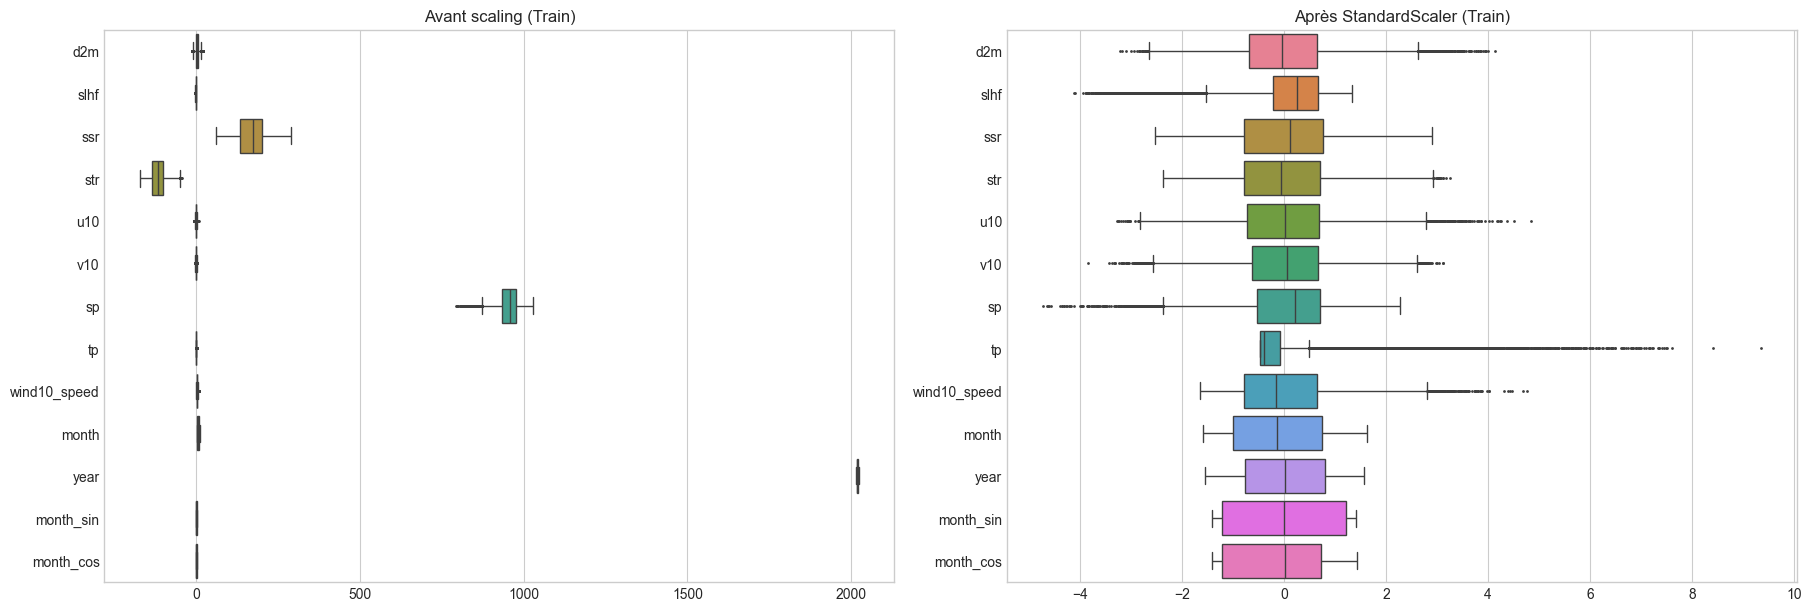

[LOG] 11. Scaling → StandardScaler ajusté sur Train


In [28]:
scaler = StandardScaler().fit(X_train_raw)
X_train = pd.DataFrame(scaler.transform(X_train_raw), columns=FEATURES, index=X_train_raw.index)
X_test  = pd.DataFrame(scaler.transform(X_test_raw),  columns=FEATURES, index=X_test_raw.index)

assert np.allclose(X_train.mean(), 0, atol=1e-6) and np.allclose(X_train.std(ddof=0), 1, atol=1e-6)
assert list(X_train.columns) == list(X_test.columns) == FEATURES
display(pd.DataFrame({"moyenne Train": X_train.mean(), "σ Train": X_train.std(ddof=0),
                      "moyenne Test": X_test.mean(), "σ Test": X_test.std(ddof=0)}).round(3).T)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
sns.boxplot(data=X_train_raw.sample(min(20_000, len(X_train_raw)), random_state=SEED), orient="h", ax=axes[0], fliersize=1); axes[0].set_title("Avant scaling (Train)")
sns.boxplot(data=X_train.sample(min(20_000, len(X_train)), random_state=SEED), orient="h", ax=axes[1], fliersize=1); axes[1].set_title("Après StandardScaler (Train)")
plt.show()
log_step("11. Scaling", "StandardScaler ajusté sur Train", moyennes=dict(zip(FEATURES, scaler.mean_.round(4).tolist())),
         ecarts_types=dict(zip(FEATURES, scaler.scale_.round(4).tolist())))

## 12. Analyse de la distribution des classes

,Train (n),Test (n),Train (%),Test (%),Total (n),Total (%)
classe,,,,,,
Froid,102139,24261,17.60,13.98,126400,16.77
Modere,251697,73255,43.37,42.21,324952,43.10
Chaud,226532,76052,39.03,43.82,302584,40.13


Ratio majoritaire / minoritaire : Train 2.46 | Test 3.13


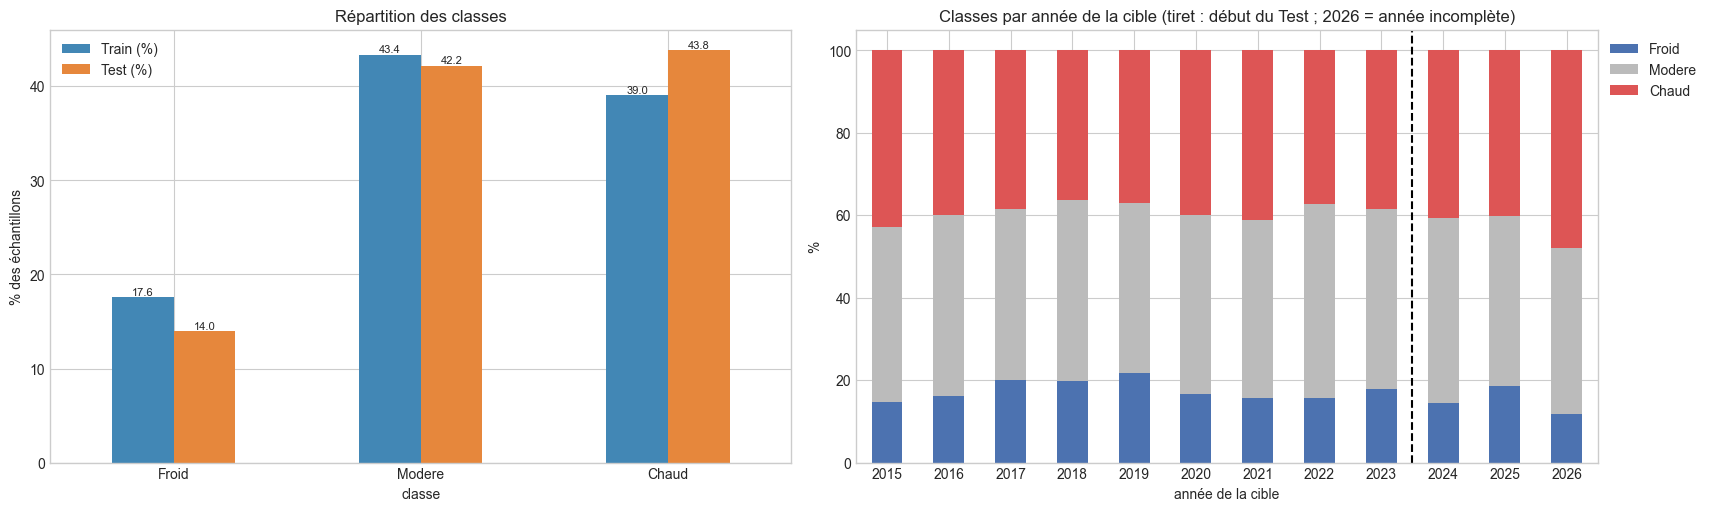

Classe minoritaire (Train) : Froid (17.6 %)
Déséquilibre marqué → voir la discussion ci-dessous
[LOG] 12. Classes → analyse des effectifs


In [29]:
def class_counts(y):
    c = y.map(dict(enumerate(CLASS_LABELS))).value_counts().reindex(CLASS_LABELS, fill_value=0)
    return c

dist = pd.DataFrame({"Train (n)": class_counts(y_train), "Test (n)": class_counts(y_test)}).rename_axis("classe")
dist["Train (%)"] = 100 * dist["Train (n)"] / dist["Train (n)"].sum()
dist["Test (%)"]  = 100 * dist["Test (n)"] / dist["Test (n)"].sum()
dist["Total (n)"] = dist["Train (n)"] + dist["Test (n)"]
dist["Total (%)"] = 100 * dist["Total (n)"] / dist["Total (n)"].sum()
display(dist.round(2))

imb_train = dist["Train (n)"].max() / max(dist["Train (n)"].min(), 1)
imb_test  = dist["Test (n)"].max() / max(dist["Test (n)"].min(), 1)
print(f"Ratio majoritaire / minoritaire : Train {imb_train:.2f} | Test {imb_test:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 5), constrained_layout=True)
dist[["Train (%)", "Test (%)"]].plot.bar(ax=axes[0], color=["#4287b5", "#e6873c"], rot=0)
axes[0].set_ylabel("% des échantillons"); axes[0].set_title("Répartition des classes")
for cont in axes[0].containers: axes[0].bar_label(cont, fmt="%.1f", fontsize=8)
by_year = pd.crosstab(df["target_time"].dt.year, df["classe"], normalize="index") * 100
by_year.plot.bar(stacked=True, ax=axes[1], color=["#4c72b0", "#bbbbbb", "#dd5555"], rot=0)
axes[1].axvline(by_year.index.get_loc(TEST_START.year) - 0.5, color="k", ls="--")
axes[1].set_ylabel("%"); axes[1].set_xlabel("année de la cible"); axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
axes[1].set_title("Classes par année de la cible (tiret : début du Test ; 2026 = année incomplète)")
plt.show()

minority = dist["Train (%)"].idxmin()
print(f"Classe minoritaire (Train) : {minority} ({dist.loc[minority, 'Train (%)']:.1f} %)")
print("Déséquilibre", "marqué" if imb_train > 1.5 else "modéré", "→ voir la discussion ci-dessous")
log_step("12. Classes", "analyse des effectifs", train=dist["Train (n)"].to_dict(), test=dist["Test (n)"].to_dict(),
         ratio_train=round(float(imb_train), 2), ratio_test=round(float(imb_test), 2))

**Discussion (conséquences pour le supervised learning)**
- Les intervalles equal-width ne garantissent pas des classes équilibrées : la classe « Froid » est minoritaire (en Algérie, les mois < ≈ 14 °C ne concernent que l'hiver du Nord et des hauts plateaux), cohérent avec l'EDA (≈ 17 %).
- La répartition **diffère entre Train et Test** : le Test (2024-2026) est plus récent et plus chaud (tendance au réchauffement visible sur `t2m` dans l'EDA). C'est un *shift* réaliste, conséquence normale d'un split chronologique — on ne le « corrige » pas, il faut l'évaluer.
- Pour les modèles :
  - l'accuracy seule serait trompeuse → rapporter aussi **F1 macro**, **balanced accuracy** et la **matrice de confusion** ;
  - `class_weight="balanced"` pour SVM et Random Forest ; vote pondéré par la distance pour KNN ;
  - si un rééchantillonnage est testé (sous-échantillonnage, SMOTE), il doit être appliqué **uniquement au Train**, jamais au Test ;
  - pour régler les hyperparamètres : validation croisée temporelle (`TimeSeriesSplit` sur les mois), pas de K-fold aléatoire stratifié (fuite temporelle).

## 13. Export du dataset prêt à l'emploi

Tout est écrit dans `data/supervised/` (les fichiers d'origine ne sont pas modifiés) :

| Fichier | Contenu |
|---|---|
| `X_train.csv`, `X_test.csv` | features standardisées (KNN, SVM, Voting, AdaBoost) |
| `X_train_unscaled.csv`, `X_test_unscaled.csv` | mêmes features non standardisées (transformations log incluses) : Random Forest, interprétation |
| `y_train.csv`, `y_test.csv` | `y` (code 0/1/2), `classe` (label), `t2m_next` (°C, pour une éventuelle régression) |
| `meta_train.csv`, `meta_test.csv` | `cell`, `lat`, `lon`, `time` (M), `target_time` (M+1), `anomaly_corrected` — pour les cartes et l'analyse d'erreurs, **jamais** comme features |
| `scaler.joblib` | le StandardScaler ajusté sur Train |
| `preprocessing_metadata.json` | paramètres, décisions, seuils, journal complet |

In [30]:
META_COLS = ["cell", "lat", "lon", "time", "target_time", "anomaly_corrected"]
Y_COLS = ["y", "classe", "t2m_next"]

files = {
    "X_train.csv": X_train, "X_test.csv": X_test,
    "X_train_unscaled.csv": X_train_raw, "X_test_unscaled.csv": X_test_raw,
    "y_train.csv": train_df[Y_COLS], "y_test.csv": test_df[Y_COLS],
    "meta_train.csv": train_df[META_COLS], "meta_test.csv": test_df[META_COLS]}
for name, frame in files.items():
    frame.to_csv(OUT_DIR / name, index=False, float_format="%.6g", date_format="%Y-%m-%d")
joblib.dump(scaler, OUT_DIR / "scaler.joblib")

metadata = {
    "cree_le": datetime.now().isoformat(timespec="seconds"),
    "source": str(DATA_REL).replace("\\", "/"),
    "environnement": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                      "xarray": xr.__version__, "sklearn": sklearn.__version__},
    "dataset": {"n_cellules": int(N), "n_mois_fichier": int(T), "lignes_total_apres_target": int(len(df))},
    "features": FEATURES, "features_physiques": PHYS_FEATURES, "features_calendaires": CALENDAR, "features_optionnelles": EXTRA,
    "variables_retirees": {"faible_variance": DROP_LOWVAR, "redondance": DROP_CORR},
    "transformations": TRANSFORMS,
    "correction_2022_2024": {"appliquee": ANOMALY_PRESENT, "facteur": K_FACTOR, "variables": ACCUM if ANOMALY_PRESENT else [],
                             "mois": [d.strftime("%Y-%m") for d in affected_times],
                             "facteurs_estimes": {k: round(v, 4) for k, v in k_by_var.items()}},
    "target": {"definition": "t2m (°C) de la meme cellule au mois M+1", "discretisation": "equal-width sur Train",
               "bornes_train": EDGES_TRAIN.round(4).tolist(), "bins_appliques": ["-inf", *EDGES_TRAIN[1:-1].round(4).tolist(), "+inf"],
               "classes": dict(enumerate(CLASS_LABELS))},
    "split": {"type": "chronologique", "test_start": str(TEST_START.date()),
              "train_features": [str(train_df['time'].min().date()), str(train_df['time'].max().date())],
              "test_features": [str(test_df['time'].min().date()), str(test_df['time'].max().date())],
              "purge": sorted(df.loc[purged, "time"].dt.strftime("%Y-%m").unique().tolist()),
              "n_train": int(len(train_df)), "n_test": int(len(test_df))},
    "scaling": {"methode": "StandardScaler (fit Train)", "mean": dict(zip(FEATURES, scaler.mean_.tolist())),
                "scale": dict(zip(FEATURES, scaler.scale_.tolist()))},
    "classes": {"train": dist["Train (n)"].astype(int).to_dict(), "test": dist["Test (n)"].astype(int).to_dict()},
    "journal": LOG}
with open(OUT_DIR / "preprocessing_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=str)
print("Fichiers écrits dans", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    if p.is_file(): print(f"  {p.name:32s} {p.stat().st_size/1e6:8.2f} Mo")

Fichiers écrits dans C:\Users\hp\Downloads\Climate_Data_Mining_Algeria\Climate_Data_Mining_Algeria\Climate_Data_Mining\data\supervised
  meta_test.csv                        7.13 Mo
  meta_train.csv                      23.84 Mo
  preprocessing_metadata.json          0.01 Mo
  scaler.joblib                        0.00 Mo
  X_test.csv                          20.66 Mo
  X_test_unscaled.csv                 17.63 Mo
  X_train.csv                         69.70 Mo
  X_train_unscaled.csv                59.01 Mo
  y_test.csv                           3.00 Mo
  y_train.csv                         10.05 Mo


In [31]:
# Relecture depuis le disque : les fichiers doivent être directement exploitables
Xtr = pd.read_csv(OUT_DIR / "X_train.csv"); Xte = pd.read_csv(OUT_DIR / "X_test.csv")
ytr = pd.read_csv(OUT_DIR / "y_train.csv"); yte = pd.read_csv(OUT_DIR / "y_test.csv")
mtr = pd.read_csv(OUT_DIR / "meta_train.csv", parse_dates=["time", "target_time"])
mte = pd.read_csv(OUT_DIR / "meta_test.csv", parse_dates=["time", "target_time"])
assert list(Xtr.columns) == list(Xte.columns) == FEATURES
assert len(Xtr) == len(ytr) == len(mtr) and len(Xte) == len(yte) == len(mte)
assert not Xtr.isna().any().any() and not Xte.isna().any().any() and not ytr["y"].isna().any() and not yte["y"].isna().any()
assert set(ytr["y"].unique()) <= set(range(N_CLASSES)) and set(yte["y"].unique()) <= set(range(N_CLASSES))
assert mtr["target_time"].max() < mte["time"].min()
assert np.allclose(joblib.load(OUT_DIR / "scaler.joblib").transform(pd.read_csv(OUT_DIR / "X_test_unscaled.csv")), Xte.values, atol=1e-3)
print("Relecture OK :", Xtr.shape, Xte.shape)

Relecture OK : (580368, 13) (173568, 13)


### Récapitulatif des décisions (journal de traçabilité)

In [32]:
recap = pd.DataFrame([{"étape": e["etape"], "décision": e["decision"]} for e in LOG])
print(recap.to_string(index=False))

                     étape                                                             décision
     2. Valeurs manquantes                                         aucune imputation nécessaire
 3. Incohérences 2022-2024                             variables accumulées × 2.000 sur 18 mois
 4a. Plausibilité physique                0 valeur(s) impossible(s) traitée(s) comme manquantes
  4b. Outliers / asymétrie aucune suppression ; transformation log des variables intermittentes
     5. Faible variabilité                      supprimées : aucune ; marquées : ['sshf', 'ro']
     6. Feature extraction                             ajout wind10_speed, month_sin, month_cos
                 7. Target                           t2m(M+1) par cellule ; dernier mois retiré
8. Corrélation / sélection                                       retirées : ['e', 'ro', 'sshf']
         9. Discrétisation                                  equal-width 3 classes, seuils Train
                 10. Split              

**Utilisation dans le notebook suivant :**
```python
import pandas as pd
D = "data/supervised/"
X_train, X_test = pd.read_csv(D+"X_train.csv"), pd.read_csv(D+"X_test.csv")
y_train, y_test = pd.read_csv(D+"y_train.csv")["y"], pd.read_csv(D+"y_test.csv")["y"]
```